# LayoutLM v3

## 1. Install necessary packages

In [4]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve()

while not (project_root / "app").is_dir():
    if project_root == project_root.parent:
        raise RuntimeError("Cannot find the project root containing app/")
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [1]:
!pip install torch transformers pandas pyarrow numpy seqeval tqdm seqeval
# !pip install seqeval tqdm

Defaulting to user installation because normal site-packages is not writeable


In [7]:
!pip install pymupdf

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 MB 58.8 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 75.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymupdf]m6/7 [pymupdf]ime]


## 2. Import packages

In [1]:
import json
import random
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from seqeval.scheme import IOB2
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer, LayoutLMv3ImageProcessor


SEED = 42
MODEL_NAME = "microsoft/layoutlmv3-base"

PARQUET_PATH = Path("../data/raw/docile.parquet")
OUTPUT_DIR = Path("../data/interim/layoutlm_experiment")

FIELDS = (
    "invoice_number",
    "invoice_date",
    "due_date",
    "seller_name",
    "client_name",
)

LABELS = ["O"] + [
    f"{prefix}-{field}"
    for field in FIELDS
    for prefix in ("B", "I")
]

LABEL2ID = {label: index for index, label in enumerate(LABELS)}
ID2LABEL = dict(enumerate(LABELS))

IGNORE_INDEX = -100
MAX_LENGTH = 512
BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 3e-5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

W1122 22:13:01.404000 28816 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: cpu


## 3. Split documents

In [3]:
df = pd.read_parquet(PARQUET_PATH)

# print("Documents:", len(df))
# print("Columns:", df.columns.tolist())

# assert df["document_id"].is_unique
# assert df.index.is_unique

In [4]:
shuffled = df.copy()
# random.Random(SEED).shuffle(shuffled)

train_df, remaining_df = train_test_split(
    df,
    test_size=0.2,
    shuffle=True,
    random_state=SEED,
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.5,
    shuffle=True,
    random_state=SEED,
)
splits = {
    'train': train_df,
    'val': val_df,
    'test': test_df
}

In [18]:
# class DocumentSplitter:
#     """Keep each template cluster in one split."""

#     def split(self, frame, seed=42):
#         groups = defaultdict(list)

#         for index, row in frame.iterrows():
#             json_data = json.loads(row['json_data'])
#             cluster = json_data["metadata"].get("cluster_id")

#             if cluster is None or pd.isna(cluster):
#                 key = ("document", row["document_id"])
#             else:
#                 key = ("cluster", cluster)

#             groups[key].append(index)

#         keys = list(groups)
#         random.Random(seed).shuffle(keys)

#         if len(keys) < 10:
#             raise ValueError("Need at least 10 template groups for this split")

#         train_end = int(len(keys) * 0.8)
#         val_end = int(len(keys) * 0.9)

#         subsets = {
#             "train": keys[:train_end],
#             "val": keys[train_end:val_end],
#             "test": keys[val_end:],
#         }

#         return {
#             name: frame.loc[
#                 [index for key in subset for index in groups[key]]
#             ].copy()
#             for name, subset in subsets.items()
#         }

In [16]:
# row = df.iloc[0]


In [19]:
# splits = DocumentSplitter().split(df, seed=SEED)
# # a
# for name, frame in splits.items():
#     print(name, len(frame))

train 4657
val 414
test 609


### Match OCR-words and annotation by geometry

In [21]:
class InvoicePreparer:
    """Build page records from OCR words and annotation boxes."""

    def __init__(self, fields=FIELDS, min_coverage=0.5):
        self.fields = fields
        self.min_coverage = min_coverage

    @staticmethod
    def validate_box(value):
        box = np.asarray(value, dtype=np.float64)

        if box.shape != (4,) or not np.isfinite(box).all():
            raise ValueError(f"Invalid box: {value}")

        x0, y0, x1, y1 = box

        if not (0 <= x0 < x1 <= 1 and 0 <= y0 < y1 <= 1):
            raise ValueError(f"Invalid normalized coordinates: {value}")

        return box

    @staticmethod
    def word_coverage(word_box, annotation_box):
        top_left = np.maximum(word_box[:2], annotation_box[:2])
        bottom_right = np.minimum(word_box[2:], annotation_box[2:])

        intersection = np.maximum(bottom_right - top_left, 0).prod()
        word_area = np.prod(word_box[2:] - word_box[:2])

        return float(intersection / word_area)

    def prepare_document(self, row):
        json_data = json.loads(row.json_data)
        metadata = json_data["metadata"]
        page_count = int(metadata["page_count"])
        annotations = []

        for field in self.fields:
            annotation = json_data["invoice"].get(field)

            if annotation is None:
                continue

            if len(annotation["pages"]) != len(annotation["bbox"]):
                raise ValueError(f"Annotation lengths differ: {field}")

            for page, box in zip(annotation["pages"], annotation["bbox"]):
                page = int(page)

                if not 0 <= page < page_count:
                    raise ValueError(f"Invalid annotation page: {page}")

                annotations.append({
                    "field": field,
                    "page": page,
                    "box": self.validate_box(box),
                })

        words_by_page = defaultdict(list)
        matched_annotations = set()

        # Preserve the OCR order used by the parquet text offsets.
        words = sorted(row.text_with_boxes, key=lambda word: word["start"])

        for word in words:
            if not word["text"].strip():
                continue

            page = int(word["page"])

            if not 0 <= page < page_count:
                raise ValueError(f"Invalid OCR page: {page}")

            box = self.validate_box(word["bbox"])
            candidates = []

            for annotation_id, annotation in enumerate(annotations):
                if annotation["page"] != page:
                    continue

                coverage = self.word_coverage(box, annotation["box"])

                if coverage >= self.min_coverage:
                    candidates.append(annotation_id)

            if len(candidates) > 1:
                raise ValueError(
                    f"Ambiguous word: {word['text']!r}, page={page}"
                )

            owner = candidates[0] if candidates else None

            if owner is not None:
                matched_annotations.add(owner)

            words_by_page[page].append({
                "text": word["text"],
                "box": (box * 1000).astype(np.int64).tolist(),
                "owner": owner,
            })

        missing = [
            annotation["field"]
            for index, annotation in enumerate(annotations)
            if index not in matched_annotations
        ]

        if missing:
            raise ValueError(f"Annotations without OCR matches: {missing}")

        if not words_by_page:
            raise ValueError("Document has no OCR words")

        records = []

        for page, page_words in sorted(words_by_page.items()):
            labels = []
            previous_owner = None

            for word in page_words:
                owner = word["owner"]

                if owner is None:
                    label = "O"
                else:
                    prefix = "I" if owner == previous_owner else "B"
                    field = annotations[owner]["field"]
                    label = f"{prefix}-{field}"

                labels.append(LABEL2ID[label])
                previous_owner = owner

            records.append({
                "document_id": row.document_id,
                "pdf_path": str(row.pdf_path),
                "page": page,
                "words": [word["text"] for word in page_words],
                "boxes": [word["box"] for word in page_words],
                "labels": labels,
            })

        return records

    def build(self, frame):
        records = []
        rejected = []

        for row in tqdm(
            frame.itertuples(index=False),
            total=len(frame),
            desc="Prepare documents",
        ):
            try:
                document_records = self.prepare_document(row)
            except ValueError as error:
                rejected.append({
                    "document_id": row.document_id,
                    "reason": str(error),
                })
                continue

            records.extend(document_records)

        return records, pd.DataFrame(
            rejected,
            columns=["document_id", "reason"],
        )

In [22]:
preparer = InvoicePreparer()
pages_by_split = {}
rejected_by_split = {}

for name, frame in splits.items():
    pages, rejected = preparer.build(frame)

    pages_by_split[name] = pages
    rejected_by_split[name] = rejected

    accepted_documents = len({page["document_id"] for page in pages})

    print(
        name,
        "accepted documents:", accepted_documents,
        "pages:", len(pages),
        "rejected documents:", len(rejected),
    )

    if not pages:
        raise ValueError(f"No accepted pages in {name}")

Prepare documents:   0%|          | 6/4544 [00:00<01:18, 57.86it/s]

Prepare documents: 100%|██████████| 4544/4544 [01:25<00:00, 53.33it/s]


train accepted documents: 4380 pages: 5655 rejected documents: 164


Prepare documents: 100%|██████████| 568/568 [00:10<00:00, 51.79it/s]


val accepted documents: 552 pages: 716 rejected documents: 16


Prepare documents: 100%|██████████| 568/568 [00:11<00:00, 51.19it/s]

test accepted documents: 547 pages: 714 rejected documents: 21


In [23]:
rejected_by_split["train"].head(20)

,document_id,reason
0,8006950cfd1b473fbf27a0bc,"Ambiguous word: 'August', page=0"
1,d12a661e877d4ef4b1c7f979,Annotations without OCR matches: ['seller_name']
2,bae9600370a44f6d954bccaf,Annotations without OCR matches: ['invoice_date']
3,98e9cfc37c1a4e96949a19ee,Annotations without OCR matches: ['invoice_dat...
4,2c93ee1b82134ddd88fb28b7,Annotations without OCR matches: ['due_date']
5,7d47467707f2441a9ae7d2de,Annotations without OCR matches: ['invoice_date']
6,2034da2080554b7885ee01e7,"Ambiguous word: 'WNIS-AM', page=0"
7,2269a9fb4fd74cb69dc14216,"Ambiguous word: 'Media', page=0"
8,b89b759330574655aeeaca39,Annotations without OCR matches: ['invoice_date']
9,8ec2e70573b147238bdfe5c5,"Ambiguous word: 'July', page=0"


In [25]:
example = pages_by_split["train"][0]

display(pd.DataFrame({
    **example
}))

,document_id,pdf_path,page,words,boxes,labels
0,2e95329f4c9e48fca33538aa,/home/ubuntu/invoices-ocr/data/raw/docile/pdfs...,0,Aug,"[184, 92, 210, 102]",3
1,2e95329f4c9e48fca33538aa,/home/ubuntu/invoices-ocr/data/raw/docile/pdfs...,0,"20,","[215, 92, 232, 101]",4
2,2e95329f4c9e48fca33538aa,/home/ubuntu/invoices-ocr/data/raw/docile/pdfs...,0,20,"[238, 92, 252, 100]",4
3,2e95329f4c9e48fca33538aa,/home/ubuntu/invoices-ocr/data/raw/docile/pdfs...,0,CONT#,"[84, 106, 130, 114]",0
4,2e95329f4c9e48fca33538aa,/home/ubuntu/invoices-ocr/data/raw/docile/pdfs...,0,34264102,"[184, 106, 245, 114]",1
...,...,...,...,...,...,...
238,2e95329f4c9e48fca33538aa,/home/ubuntu/invoices-ocr/data/raw/docile/pdfs...,0,0.00,"[896, 855, 924, 863]",0
239,2e95329f4c9e48fca33538aa,/home/ubuntu/invoices-ocr/data/raw/docile/pdfs...,0,NSL,"[84, 870, 109, 878]",0
240,2e95329f4c9e48fca33538aa,/home/ubuntu/invoices-ocr/data/raw/docile/pdfs...,0,0.00,"[896, 870, 924, 879]",0
241,2e95329f4c9e48fca33538aa,/home/ubuntu/invoices-ocr/data/raw/docile/pdfs...,0,TOTAL,"[83, 885, 127, 894]",0


## 4. PyTorch Dataset

In [26]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True,
)
image_processor = LayoutLMv3ImageProcessor.from_pretrained(
    MODEL_NAME,
    apply_ocr=False,
)

assert tokenizer.is_fast

In [27]:
df.columns

Index(['document_id', 'ocr_text', 'text_with_boxes', 'json_data', 'pdf_path',
       'split'],
      dtype='str')

In [28]:
import pymupdf
from PIL import Image

IMAGE_CACHE = Path("../data/interim/docile_images")


def load_page_image(page, dpi=150):
    cache_path = (
        IMAGE_CACHE
        / f"dpi_{dpi}"
        / page["document_id"]
        / f"page_{int(page['page']):04d}.png"
    )

    if cache_path.is_file():
        with Image.open(cache_path) as image:
            return image.convert("RGB")

    with pymupdf.open(page["pdf_path"]) as document:
        pdf_page = document.load_page(int(page["page"]))
        pixmap = pdf_page.get_pixmap(
            dpi=dpi,
            colorspace=pymupdf.csRGB,
            alpha=False,
        )
        image = Image.frombytes(
            "RGB",
            (pixmap.width, pixmap.height),
            pixmap.samples,
        )

    cache_path.parent.mkdir(parents=True, exist_ok=True)
    image.save(cache_path)
    return image

In [29]:
pages_by_split['train'][0].keys()

dict_keys(['document_id', 'pdf_path', 'page', 'words', 'boxes', 'labels'])

In [31]:
for split, pages in pages_by_split.items():
    for page in tqdm(pages, desc=f"Cache {split} images"):
        load_page_image(page)

Cache test images: 100%|██████████| 714/714 [02:08<00:00,  5.57it/s]


In [32]:
class InvoiceDataset(Dataset):
    """Cache complete-word windows and retain page coordinates for evaluation."""

    def __init__(self, pages, tokenizer, image_processor, max_length=512):
        if not 4 <= max_length <= 512:
            raise ValueError("max_length must be between 4 and 512")

        self.pages = pages
        self.samples = []

        capacity = (
            max_length
            - tokenizer.num_special_tokens_to_add(pair=False)
        )

        for page_index, page in enumerate(tqdm(pages, desc="Tokenize pages")):
            encoded = tokenizer(
                page["words"],
                boxes=page["boxes"],
                add_special_tokens=False,
                truncation=False,
                return_attention_mask=False,
                return_token_type_ids=False,
            )
            image = load_page_image(page).convert("RGB")

            pixel_values = image_processor(
                images=image,
                return_tensors="pt",
            )["pixel_values"][0]

            pieces = [[] for _ in page["words"]]

            for token_id, word_id in zip(
                encoded["input_ids"],
                encoded.word_ids(),
            ):
                pieces[word_id].append(token_id)

            if any(not tokens or len(tokens) > capacity for tokens in pieces):
                raise ValueError(
                    f"Empty or overlong word: "
                    f"{page['document_id']}, page={page['page']}"
                )

            start = 0

            while start < len(pieces):
                end = start
                token_count = 0

                while (
                    end < len(pieces)
                    and token_count + len(pieces[end]) <= capacity
                ):
                    token_count += len(pieces[end])
                    end += 1

                input_ids = [tokenizer.cls_token_id]
                boxes = [[0, 0, 0, 0]]
                labels = [IGNORE_INDEX]
                word_ids = [-1]

                for word_id in range(start, end):
                    tokens = pieces[word_id]
                    continuation_count = len(tokens) - 1

                    input_ids.extend(tokens)
                    boxes.extend([page["boxes"][word_id]] * len(tokens))
                    labels.extend(
                        [page["labels"][word_id]]
                        + [IGNORE_INDEX] * continuation_count
                    )
                    word_ids.extend(
                        [word_id] + [-1] * continuation_count
                    )

                input_ids.append(tokenizer.sep_token_id)
                boxes.append([1000, 1000, 1000, 1000])
                labels.append(IGNORE_INDEX)
                word_ids.append(-1)

                attention_mask = [1] * len(input_ids)
                padding = max_length - len(input_ids)

                sample = {
                    "input_ids": (
                        input_ids + [tokenizer.pad_token_id] * padding
                    ),
                    "attention_mask": attention_mask + [0] * padding,
                    "bbox": boxes + [[0, 0, 0, 0]] * padding,
                    "labels": labels + [IGNORE_INDEX] * padding,
                    "word_ids": word_ids + [-1] * padding,
                    "page_index": page_index
                }
                sample = {
                    key: torch.tensor(value, dtype=torch.long)
                    for key, value in sample.items()
                }
                sample["pixel_values"] = pixel_values

                self.samples.append(sample)

                start = end

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        return self.samples[index]

In [33]:
datasets = {
    name: InvoiceDataset(pages, tokenizer, image_processor, MAX_LENGTH)
    for name, pages in pages_by_split.items()
}

loaders = {
    name: DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=name == "train",
        num_workers=0,
        pin_memory=device.type == "cuda",
    )
    for name, dataset in datasets.items()
}

batch = next(iter(loaders["train"]))

for name, tensor in batch.items():
    print(name, tuple(tensor.shape))

Tokenize pages: 100%|██████████| 714/714 [00:40<00:00, 17.64it/s]


input_ids (16, 512)
attention_mask (16, 512)
bbox (16, 512, 4)
labels (16, 512)
word_ids (16, 512)
page_index (16,)
pixel_values (16, 3, 224, 224)


## 5. Model wrapper

In [41]:
class LayoutLMFieldExtractor(nn.Module):
    """Predict one BIO label per text token using text, boxes, and page images."""

    def __init__(self, model_name, num_labels, id2label, label2id):
        super().__init__()

        self.backbone = AutoModel.from_pretrained(
            model_name,
            num_labels=num_labels,
            id2label=id2label,
            label2id=label2id,
        )
        self.dropout = nn.Dropout(
            self.backbone.config.hidden_dropout_prob
        )
        self.classifier = nn.Linear(
            self.backbone.config.hidden_size,
            num_labels,
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        bbox,
        pixel_values,
    ):
        outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask,
            bbox=bbox,
            pixel_values=pixel_values,
            return_dict=True,
        )

        # Visual tokens follow text tokens in the backbone output.
        text_hidden = outputs.last_hidden_state[:, :input_ids.shape[1]]

        return self.classifier(self.dropout(text_hidden))

In [42]:
model = LayoutLMFieldExtractor(
    model_name=MODEL_NAME,
    num_labels=len(LABELS),
    id2label=ID2LABEL,
    label2id=LABEL2ID
).to(device)

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 212/212 [00:00<00:00, 5025.76it/s]


## 6. Metrics, `train_one_epoch`, `eval_one_epoch`, `train`

### Metrics

* `loss`
* `bio_word_accuracy`
* `field_word_micro_precision/recall/f1`
* `field_word_macro_f1`
* `per_field`
* `entity_precision/recall/f1`

Main metrcic for checkpoint selection `entity_f1`

In [36]:
class EpochMetrics:
    """Accumulate word metrics without retaining model outputs."""

    def __init__(self):
        self.confusion = torch.zeros(
            len(LABELS),
            len(LABELS),
            dtype=torch.long,
        )
        self.loss_sum = 0.0
        self.word_count = 0

    def update(self, logits, labels, loss):
        valid = labels != IGNORE_INDEX

        truth = labels[valid].detach().cpu()
        predicted = logits.argmax(dim=-1)[valid].detach().cpu()

        size = len(LABELS)
        counts = torch.bincount(
            truth * size + predicted,
            minlength=size * size,
        )

        self.confusion += counts.reshape(size, size)
        self.loss_sum += loss.detach().item() * truth.numel()
        self.word_count += truth.numel()

    def compute(self):
        if self.word_count == 0:
            raise ValueError("No supervised words")

        # Map O -> 0, B/I of each field -> one field ID.
        mapping = [0] + [
            field_id
            for field_id in range(1, len(FIELDS) + 1)
            for _ in range(2)
        ]

        matrix = torch.zeros(
            len(FIELDS) + 1,
            len(FIELDS) + 1,
            dtype=torch.float64,
        )

        for truth_id, truth_field in enumerate(mapping):
            for pred_id, pred_field in enumerate(mapping):
                matrix[truth_field, pred_field] += (
                    self.confusion[truth_id, pred_id]
                )

        tp = matrix.diag()[1:]
        fp = matrix.sum(dim=0)[1:] - tp
        fn = matrix.sum(dim=1)[1:] - tp

        precision = tp / (tp + fp).clamp_min(1)
        recall = tp / (tp + fn).clamp_min(1)
        f1 = 2 * tp / (2 * tp + fp + fn).clamp_min(1)

        active = (tp + fp + fn) > 0

        return {
            "loss": self.loss_sum / self.word_count,
            "bio_word_accuracy": (
                self.confusion.diag().sum().item() / self.word_count
            ),
            "field_word_micro_precision": (
                tp.sum() / (tp + fp).sum().clamp_min(1)
            ).item(),
            "field_word_micro_recall": (
                tp.sum() / (tp + fn).sum().clamp_min(1)
            ).item(),
            "field_word_micro_f1": (
                2 * tp.sum() / (2 * tp + fp + fn).sum().clamp_min(1)
            ).item(),
            "field_word_macro_f1": (
                f1[active].mean().item() if active.any() else 0.0
            ),
            "per_field": {
                field: {
                    "precision": precision[index].item(),
                    "recall": recall[index].item(),
                    "f1": f1[index].item(),
                    "support": int((tp + fn)[index].item()),
                }
                for index, field in enumerate(FIELDS)
            },
        }

In [37]:
def move_inputs(batch, device):
    return {
        key: batch[key].to(device, non_blocking=True)
        for key in ("input_ids", "attention_mask", "bbox", "pixel_values")
    }


def train_one_epoch(model, loader, optimizer, criterion, scheduler, device):
    model.train()
    metrics = EpochMetrics()

    for batch in tqdm(loader, desc="Train", leave=False):
        inputs = move_inputs(batch, device)
        labels = batch["labels"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(**inputs)
        loss = criterion(
            logits.reshape(-1, logits.shape[-1]),
            labels.reshape(-1),
        )

        if not torch.isfinite(loss):
            raise FloatingPointError("Training loss is not finite")

        loss.backward()

        nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
            error_if_nonfinite=True,
        )

        optimizer.step()
        scheduler.step()
        metrics.update(logits, labels, loss)

    return metrics.compute()


@torch.inference_mode()
def eval_one_epoch(model, loader, criterion, device):
    model.eval()

    metrics = EpochMetrics()
    word_predictions = {}

    for batch in tqdm(loader, desc="Evaluate", leave=False):
        inputs = move_inputs(batch, device)
        labels = batch["labels"].to(device, non_blocking=True)

        logits = model(**inputs)
        loss = criterion(
            logits.reshape(-1, logits.shape[-1]),
            labels.reshape(-1),
        )

        if not torch.isfinite(loss):
            raise FloatingPointError("Evaluation loss is not finite")

        metrics.update(logits, labels, loss)
        predicted = logits.argmax(dim=-1).cpu()

        for batch_index, page_index in enumerate(
            batch["page_index"].tolist()
        ):
            for token_index, word_index in enumerate(
                batch["word_ids"][batch_index].tolist()
            ):
                if word_index < 0:
                    continue

                key = (page_index, word_index)

                if key in word_predictions:
                    raise ValueError("A word was evaluated more than once")

                word_predictions[key] = predicted[
                    batch_index, token_index
                ].item()

    # Restore complete pages before measuring entity boundaries.
    true_sequences = []
    pred_sequences = []

    for page_index, page in enumerate(loader.dataset.pages):
        true_sequences.append([
            ID2LABEL[label]
            for label in page["labels"]
        ])

        pred_sequences.append([
            ID2LABEL[word_predictions[(page_index, word_index)]]
            for word_index in range(len(page["words"]))
        ])

    result = metrics.compute()

    for name, metric in (
        ("precision", precision_score),
        ("recall", recall_score),
        ("f1", f1_score),
    ):
        result[f"entity_{name}"] = metric(
            true_sequences,
            pred_sequences,
            mode="strict",
            scheme=IOB2,
            zero_division=0,
        )

    result["entity_report"] = classification_report(
        true_sequences,
        pred_sequences,
        mode="strict",
        scheme=IOB2,
        output_dict=True,
        zero_division=0,
    )

    return result

strict `IOB2` учитывает ошибки границ: например, `I-seller_name` после O не исправляется автоматически в `B-seller_name`.

In [38]:
def train(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    criterion,
    device,
    output_dir,
    epochs=5,
):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    model.to(device)

    history = []
    best_f1 = -1.0
    checkpoint_path = output_dir / "best.pt"

    for epoch in range(1, epochs + 1):
        train_metrics = train_one_epoch(
            model=model,
            loader=train_loader, 
            optimizer=optimizer,
            criterion=criterion,
            scheduler=scheduler,
            device=device
        )
        val_metrics = eval_one_epoch(
            model=model,
            loader=val_loader, 
            criterion=criterion,
            device=device
        )
        epoch_metrics = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            **{
                f"validation_{key}": value
                for key, value in val_metrics.items()
                if key != "per_entity"
            },
        }

        history.append(epoch_metrics)
        pd.DataFrame(history).to_csv(
            output_dir / "history.csv",
            index=False,
        )

        print(
            f"Epoch {epoch}/{epochs} | "
            f"train loss={train_metrics['loss']:.4f} | "
            f"val loss={val_metrics['loss']:.4f} | "
            f"val entity F1={val_metrics['entity_f1']:.4f}"
        )

        if val_metrics["entity_f1"] > best_f1:
            best_f1 = float(val_metrics["entity_f1"])

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "model_name": MODEL_NAME,
                    "labels": LABELS,
                    "fields": list(FIELDS),
                    "max_length": MAX_LENGTH,
                    "epoch": epoch,
                    "val_entity_f1": best_f1,
                },
                checkpoint_path,
            )

        # (output_dir / "history.json").write_text(
        #     json.dumps(history, indent=2),
        #     encoding="utf-8",
        # )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True,
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    return pd.DataFrame(history)

In [52]:
# import importlib.metadata


# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# tokenizer.save_pretrained(OUTPUT_DIR / "tokenizer")

# config = {
#     "model_name": MODEL_NAME,
#     "fields": list(FIELDS),
#     "labels": LABELS,
#     "seed": SEED,
#     "max_length": MAX_LENGTH,
#     "batch_size": BATCH_SIZE,
#     "epochs": EPOCHS,
#     "learning_rate": LEARNING_RATE,
#     "min_word_coverage": preparer.min_coverage,
#     "split": "template_cluster_80_10_10",
#     "versions": {
#         package: importlib.metadata.version(package)
#         for package in (
#             "torch", "transformers", "pandas", "numpy", "seqeval"
#         )
#     },
# }

# (OUTPUT_DIR / "config.json").write_text(
#     json.dumps(config, indent=2),
#     encoding="utf-8",
# )

713

In [53]:
# split_manifest = []

# for name, frame in splits.items():
#     rejected_ids = set(rejected_by_split[name]["document_id"])

#     split_manifest.extend({
#         "document_id": document_id,
#         "split": name,
#         "accepted": document_id not in rejected_ids,
#     } for document_id in frame["document_id"])

#     rejected_by_split[name].to_csv(
#         OUTPUT_DIR / f"{name}_rejected.csv",
#         index=False,
#     )

# pd.DataFrame(split_manifest).to_csv(
#     OUTPUT_DIR / "split_manifest.csv",
#     index=False,
# )

In [43]:
from transformers import get_linear_schedule_with_warmup

epochs = 20
learning_rate = 3e-5
decay = []
no_decay = []

model = LayoutLMFieldExtractor(
    model_name=MODEL_NAME,
    num_labels=len(LABELS),
    id2label=ID2LABEL,
    label2id=LABEL2ID
).to(device)

for name, parameter in model.named_parameters():
    if not parameter.requires_grad:
        continue

    if parameter.ndim < 2:
        no_decay.append(parameter)
    else:
        decay.append(parameter)

optimizer = torch.optim.AdamW(
    [
        {"params": decay, "weight_decay": 0.01},
        {"params": no_decay, "weight_decay": 0.0},
    ],
    lr=learning_rate,
)

total_steps = epochs * len(loaders["train"])
warmup_steps = int(0.1 * total_steps)  # Start with 10% warmup.

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)
criterion = nn.CrossEntropyLoss(ignore_index=-100)

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 212/212 [00:00<00:00, 5448.58it/s]


In [ ]:
history = train(
    model=model,
    train_loader=loaders["train"],
    val_loader=loaders["val"],
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    device=device,

    output_dir=OUTPUT_DIR,
    epochs=epochs
)

Epoch 1/20 | train loss=0.3576 | val loss=0.0408 | val entity F1=0.7647


Epoch 2/20 | train loss=0.0312 | val loss=0.0271 | val entity F1=0.8584


Epoch 3/20 | train loss=0.0221 | val loss=0.0263 | val entity F1=0.8685


Epoch 4/20 | train loss=0.0176 | val loss=0.0223 | val entity F1=0.8963


Epoch 5/20 | train loss=0.0142 | val loss=0.0240 | val entity F1=0.9018


Epoch 6/20 | train loss=0.0120 | val loss=0.0238 | val entity F1=0.8952


Train:  43%|████▎     | 220/511 [02:56<03:52,  1.25it/s]

In [55]:
history.to_csv('../data/interim/history_20_epochs.csv')

NameError: name 'history' is not defined

In [ ]:
test_metrics = eval_one_epoch(
    model=model,
    loader=loaders["test"],
    device=device,
)

display(pd.Series({
    key: value
    for key, value in test_metrics.items()
    if not isinstance(value, dict)
}))

display(pd.DataFrame(test_metrics["per_field"]).T)
display(pd.DataFrame(test_metrics["entity_report"]).T)

(OUTPUT_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2),
    encoding="utf-8",
)

## Debug

Recent training run from 21.11.2026 revealed significant problem with InvoicesBuilder class - it rejects too many invoices due to word boxes overlapping (eg marked entity text is found in 
multiple word boxes)

Examples of such documents are:

1. `2e95329f4c9e48fca33538aa`
2. `bc0f7fa9819741c0b1efdc34`
3. `26f0e3a78e26450b9b47dd81`

In [8]:
document_ids = ["2e95329f4c9e48fca33538aa", "bc0f7fa9819741c0b1efdc34", "26f0e3a78e26450b9b47dd81"]

In [3]:
df = pd.read_parquet("../data/interim/docile-trainval-preprocessed.parquet")

In [5]:
import pandas as pd

from app.extraction.enums import FIELD_TO_ENTITY
from app.extraction.layoutlm.preprocess import BoxGeometry, CollectAnnotations
from app.pipelines.preprocess import DecodeDocuments


def check_word_coverage(row, min_coverage=0.5):
    """Check annotation coverage for one invoice.

    Args:
        row: A row with document_id, json_data, and text_with_boxes.
        min_coverage: Minimum word-area coverage needed for a match.

    Returns:
        DataFrames of processed words and rejection details.
    """
    if not 0 < min_coverage <= 1:
        raise ValueError("min_coverage must be greater than 0 and at most 1")

    row = DecodeDocuments()(pd.DataFrame([row])).iloc[0]
    processed, rejected = [], []
    matched_annotations = set()
    word_count = 0

    try:
        annotations = CollectAnnotations(FIELD_TO_ENTITY).process(row)
        page_count = int(row.json_data["metadata"]["page_count"])
    except ValueError as error:
        return pd.DataFrame(), pd.DataFrame([{"reason": str(error)}])

    for word in sorted(row.text_with_boxes, key=lambda value: value["start"]):
        if not word["text"].strip():
            continue
        word_count += 1

        record = {
            "document_id": row.document_id,
            "text": word["text"],
            "page": word["page"],
            "bbox": word["bbox"],
        }

        try:
            box = BoxGeometry.validate_box(word["bbox"])
            page = int(word["page"])
            if not 0 <= page < page_count:
                raise ValueError(f"Invalid OCR page: {page}")
        except ValueError as error:
            rejected.append({**record, "reason": str(error)})
            continue

        matches = []
        for index, annotation in enumerate(annotations):
            if annotation["page"] != page:
                continue

            coverage = BoxGeometry.word_coverage(box, annotation["box"])
            if coverage >= min_coverage:
                matches.append({
                    "annotation_id": index,
                    "field": annotation["field"],
                    "annotation_bbox": annotation["box"].tolist(),
                    "coverage": coverage,
                })

        if len(matches) > 1:
            rejected.append({
                **record,
                "reason": "ambiguous_word",
                "matches": matches,
            })
            continue

        match = matches[0] if matches else None
        if match:
            matched_annotations.add(match["annotation_id"])

        processed.append({
            **record,
            "field": match["field"] if match else "O",
            "coverage": match["coverage"] if match else None,
            "annotation_bbox": match["annotation_bbox"] if match else None,
        })

    for index, annotation in enumerate(annotations):
        if index not in matched_annotations:
            rejected.append({
                "document_id": row.document_id,
                "reason": "annotation_without_assigned_words",
                "annotation_id": index,
                "field": annotation["field"],
                "page": annotation["page"],
                "bbox": annotation["box"].tolist(),
            })

    if word_count == 0:
        rejected.append({
            "document_id": row.document_id,
            "reason": "no_ocr_words",
        })

    return pd.DataFrame(processed), pd.DataFrame(rejected)

In [11]:
documents_df = df[df['document_id'].isin(document_ids)]
documents_df

,document_id,json_data,pdf_path,split,text_with_boxes,ocr_text
905,26f0e3a78e26450b9b47dd81,"{""invoice"": {""invoice_number"": {""value"": ""4969...",pdfs/26f0e3a78e26450b9b47dd81.pdf,train,"[{'text': 'SONNY', 'bbox': [0.7870588235294118...",SONNY CUMULUS MUSKEGON 975 INVOICE Remit To: 3...
1071,2e95329f4c9e48fca33538aa,"{""invoice"": {""invoice_number"": {""value"": ""3426...",pdfs/2e95329f4c9e48fca33538aa.pdf,train,"[{'text': 'Aug', 'bbox': [0.18411764705882352,...","Aug 20, 20 CONT# 34264102 Mod# Ver# 1 (Last=) ..."
4119,bc0f7fa9819741c0b1efdc34,"{""invoice"": {""invoice_number"": {""value"": ""4389...",pdfs/bc0f7fa9819741c0b1efdc34.pdf,train,"[{'text': 'KQMA', 'bbox': [0.27602905569007263...",KQMA 92.5 FM KKAN 1490 AM POBOX548 We certify ...


In [12]:
processed, rejected = check_word_coverage(documents_df.iloc[0])
processed.shape, rejected.shape

((840, 7), (10, 8))

In [15]:
rejected

,document_id,text,page,bbox,reason,matches,annotation_id,field
0,26f0e3a78e26450b9b47dd81,FRIENDS,0,"[0.11941176470588236, 0.21136363636363636, 0.1...",ambiguous_word,"[{'annotation_id': 0, 'field': 'CLIENT_ADDRESS...",NaN,NaN
1,26f0e3a78e26450b9b47dd81,OF,0,"[0.1952941176470588, 0.21136363636363636, 0.21...",ambiguous_word,"[{'annotation_id': 0, 'field': 'CLIENT_ADDRESS...",NaN,NaN
2,26f0e3a78e26450b9b47dd81,JON,0,"[0.2211764705882353, 0.21136363636363636, 0.25...",ambiguous_word,"[{'annotation_id': 0, 'field': 'CLIENT_ADDRESS...",NaN,NaN
3,26f0e3a78e26450b9b47dd81,BUMSTEAD*,0,"[0.2611764705882353, 0.21136363636363636, 0.35...",ambiguous_word,"[{'annotation_id': 0, 'field': 'CLIENT_ADDRESS...",NaN,NaN
4,26f0e3a78e26450b9b47dd81,FRIENDS,1,"[0.11941176470588236, 0.21136363636363636, 0.1...",ambiguous_word,"[{'annotation_id': 1, 'field': 'CLIENT_ADDRESS...",NaN,NaN
5,26f0e3a78e26450b9b47dd81,OF,1,"[0.1952941176470588, 0.21136363636363636, 0.21...",ambiguous_word,"[{'annotation_id': 1, 'field': 'CLIENT_ADDRESS...",NaN,NaN
6,26f0e3a78e26450b9b47dd81,JON,1,"[0.2211764705882353, 0.21136363636363636, 0.25...",ambiguous_word,"[{'annotation_id': 1, 'field': 'CLIENT_ADDRESS...",NaN,NaN
7,26f0e3a78e26450b9b47dd81,BUMSTEAD*,1,"[0.2611764705882353, 0.21136363636363636, 0.35...",ambiguous_word,"[{'annotation_id': 1, 'field': 'CLIENT_ADDRESS...",NaN,NaN
8,26f0e3a78e26450b9b47dd81,NaN,0,"[0.11209677419354838, 0.2057356608478803, 0.35...",annotation_without_assigned_words,NaN,2.0,CLIENT_NAME
9,26f0e3a78e26450b9b47dd81,NaN,1,"[0.11209677419354838, 0.2057356608478803, 0.35...",annotation_without_assigned_words,NaN,3.0,CLIENT_NAME


In [14]:
rejected.iloc[0]['matches']

[{'annotation_id': 0,
  'field': 'CLIENT_ADDRESS',
  'annotation_bbox': [0.11407670815341632,
   0.2062562534600363,
   0.3595453390906782,
   0.280256588670889],
  'coverage': 1.0},
 {'annotation_id': 2,
  'field': 'CLIENT_NAME',
  'annotation_bbox': [0.11209677419354838,
   0.2057356608478803,
   0.3588709677419355,
   0.2227882432411842],
  'coverage': 1.0}]

Let us display it on the invoice image:

In [16]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image


def show_boxes(image_path, annotations):
    """Display normalized annotation boxes on an invoice image."""
    with Image.open(image_path) as image:
        image = image.convert("RGB")

    width, height = image.size
    fig, ax = plt.subplots(figsize=(12, 16))
    ax.imshow(image)

    colors = ["red", "blue", "green", "orange"]

    for annotation, color in zip(
        annotations,
        (colors[i % len(colors)] for i in range(len(annotations))),
    ):
        x0, y0, x1, y1 = annotation["annotation_bbox"]
        x, y = x0 * width, y0 * height
        box_width = (x1 - x0) * width
        box_height = (y1 - y0) * height

        ax.add_patch(Rectangle(
            (x, y),
            box_width,
            box_height,
            edgecolor=color,
            facecolor=color,
            alpha=0.2,
            linewidth=2,
        ))

        ax.text(
            x, y - 5,
            annotation["field"],
            color=color,
            fontsize=10,
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
        )

    ax.axis("off")
    plt.show()

In [22]:
rejected.iloc[0]['matches']

[{'annotation_id': 0,
  'field': 'CLIENT_ADDRESS',
  'annotation_bbox': [0.11407670815341632,
   0.2062562534600363,
   0.3595453390906782,
   0.280256588670889],
  'coverage': 1.0},
 {'annotation_id': 2,
  'field': 'CLIENT_NAME',
  'annotation_bbox': [0.11209677419354838,
   0.2057356608478803,
   0.3588709677419355,
   0.2227882432411842],
  'coverage': 1.0}]

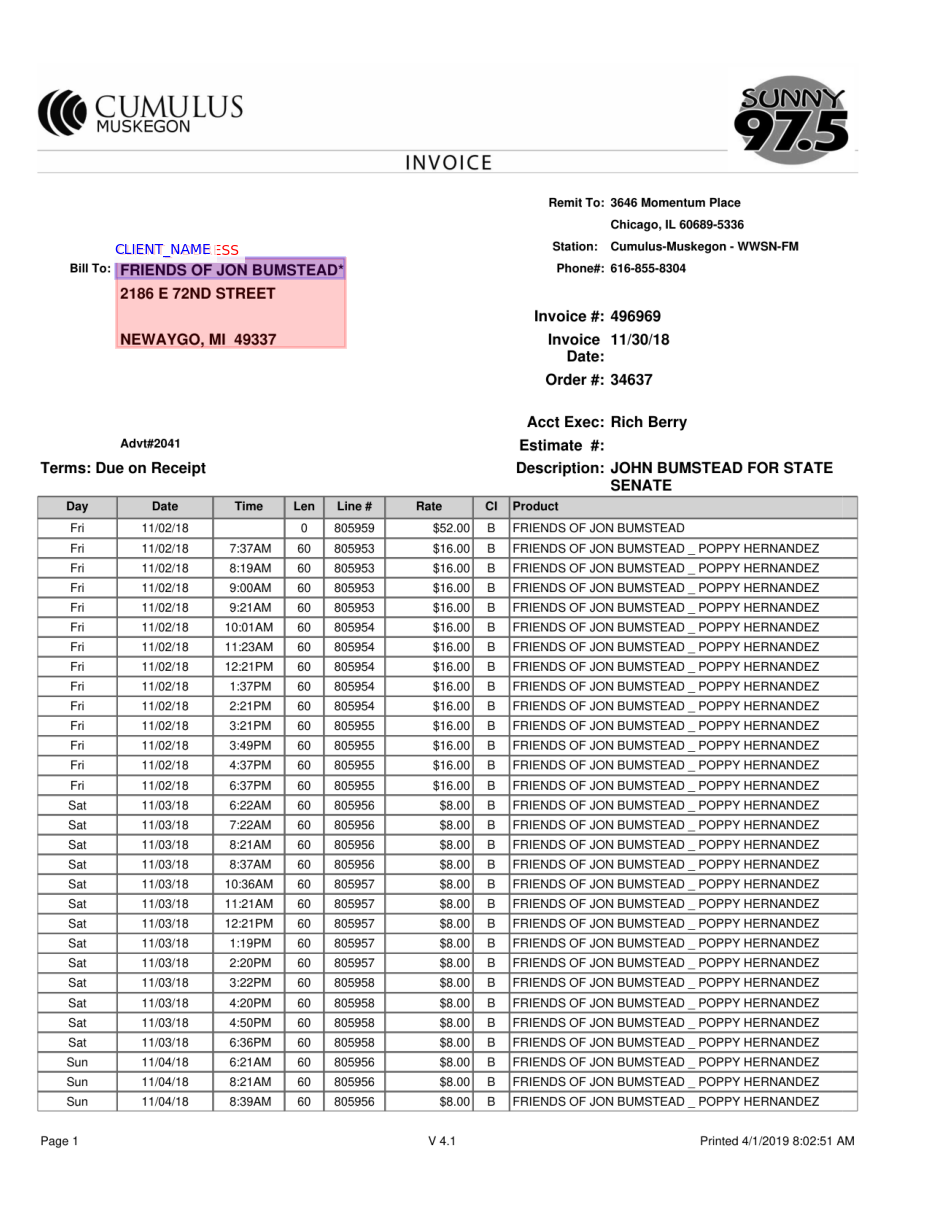

In [27]:
image_path  = "../data/interim/overlap_invoices/26f0e3a78e26450b9b47dd81/page_0000.png"
show_boxes(image_path, rejected.iloc[0]['matches'])

From the image, it is visible, that `CLIENT_ADDRESS` box covers the whole block, including `CLIENT_NAME`

Let us try `smallest area wins` approach

In [28]:
def box_area(b):
  return max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])


def intersection_area(b1, b2):
  x0 = max(b1[0], b2[0])
  y0 = max(b1[1], b2[1])
  x1 = min(b1[2], b2[2])
  y1 = min(b1[3], b2[3])
  return max(0.0, x1 - x0) * max(0.0, y1 - y0)

In [31]:
row = documents_df.iloc[0]
row

document_id                                 26f0e3a78e26450b9b47dd81
json_data          {"invoice": {"invoice_number": {"value": "4969...
pdf_path                           pdfs/26f0e3a78e26450b9b47dd81.pdf
split                                                          train
text_with_boxes    [{'text': 'SONNY', 'bbox': [0.7870588235294118...
ocr_text           SONNY CUMULUS MUSKEGON 975 INVOICE Remit To: 3...
Name: 905, dtype: object

In [35]:
row = documents_df.iloc[0]
row = DecodeDocuments()(pd.DataFrame([row])).iloc[0]
annotations = CollectAnnotations(FIELD_TO_ENTITY).process(row)
word_boxes = row['text_with_boxes']

In [38]:
annotations[:5]

[{'field': 'CLIENT_ADDRESS',
  'page': 0,
  'box': array([0.11407671, 0.20625625, 0.35954534, 0.28025659])},
 {'field': 'CLIENT_ADDRESS',
  'page': 1,
  'box': array([0.11509525, 0.20783073, 0.35954534, 0.28183106])},
 {'field': 'CLIENT_NAME',
  'page': 0,
  'box': array([0.11209677, 0.20573566, 0.35887097, 0.22278824])},
 {'field': 'CLIENT_NAME',
  'page': 1,
  'box': array([0.11209677, 0.20573566, 0.35887097, 0.2244389 ])},
 {'field': 'SELLER_NAME',
  'page': 0,
  'box': array([0.08657607, 0.06376625, 0.21129032, 0.10473815])}]

In [44]:
friends_boxes = list(filter(lambda x: x['text'] == 'FRIENDS', word_boxes))
friends_boxes, len(friends_boxes)

([{'text': 'FRIENDS',
   'bbox': [0.11941176470588236,
    0.21136363636363636,
    0.18823529411764706,
    0.22090909090909092],
   'page': 0,
   'start': 131,
   'end': 138,
   'confidence': 0.9998292922973633,
   'block_index': 4,
   'line_index': 0,
   'word_index': 2},
  {'text': 'FRIENDS',
   'bbox': [0.5417647058823529,
    0.4268181818181818,
    0.5958823529411764,
    0.43454545454545457],
   'page': 0,
   'start': 452,
   'end': 459,
   'confidence': 0.9996747970581055,
   'block_index': 11,
   'line_index': 0,
   'word_index': 2},
  {'text': 'FRIENDS',
   'bbox': [0.5417647058823529,
    0.4431818181818182,
    0.5958823529411764,
    0.4509090909090909],
   'page': 0,
   'start': 515,
   'end': 522,
   'confidence': 0.9943705201148987,
   'block_index': 12,
   'line_index': 0,
   'word_index': 2},
  {'text': 'FRIENDS',
   'bbox': [0.5417647058823529,
    0.45954545454545453,
    0.5958823529411764,
    0.4672727272727273],
   'page': 0,
   'start': 594,
   'end': 601,
   

In [48]:
friends_boxes

[{'text': 'FRIENDS',
  'bbox': [0.11941176470588236,
   0.21136363636363636,
   0.18823529411764706,
   0.22090909090909092],
  'page': 0,
  'start': 131,
  'end': 138,
  'confidence': 0.9998292922973633,
  'block_index': 4,
  'line_index': 0,
  'word_index': 2},
 {'text': 'FRIENDS',
  'bbox': [0.5417647058823529,
   0.4268181818181818,
   0.5958823529411764,
   0.43454545454545457],
  'page': 0,
  'start': 452,
  'end': 459,
  'confidence': 0.9996747970581055,
  'block_index': 11,
  'line_index': 0,
  'word_index': 2},
 {'text': 'FRIENDS',
  'bbox': [0.5417647058823529,
   0.4431818181818182,
   0.5958823529411764,
   0.4509090909090909],
  'page': 0,
  'start': 515,
  'end': 522,
  'confidence': 0.9943705201148987,
  'block_index': 12,
  'line_index': 0,
  'word_index': 2},
 {'text': 'FRIENDS',
  'bbox': [0.5417647058823529,
   0.45954545454545453,
   0.5958823529411764,
   0.4672727272727273],
  'page': 0,
  'start': 594,
  'end': 601,
  'confidence': 0.5948008894920349,
  'block_in

In [65]:
min_coverage = 0.5
results = []

for word in friends_boxes:
    w_box = word['bbox']
    w_area = box_area(w_box)

    if w_area == 0:
        continue
    
    candidates = []
    for ann in annotations:
        coverage = intersection_area(w_box, ann['box']) / w_area
        if coverage >= min_coverage:
            candidates.append({
            "label": ann["field"],
            "ann_area": box_area(ann["box"]),
        })
    if not candidates:
        results.append((word["text"], "O"))
        continue

    candidates.sort(key=lambda x: x["ann_area"])
    best_label = candidates[0]["label"]
    results.append((word["text"], best_label))

# Выводим результат для каждого слова
for text, label in results:
  print(f"{text}: {label}")
# results

FRIENDS: CLIENT_NAME
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: CLIENT_NAME
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O
FRIENDS: O


Now let us edit initial function in order to verify, it will decrease number of rejected items:

In [71]:
def check_word_coverage_by_area(row, min_coverage=0.5):
    """Check annotation coverage for one invoice.

    Args:
        row: A row with document_id, json_data, and text_with_boxes.
        min_coverage: Minimum word-area coverage needed for a match.

    Returns:
        DataFrames of processed words and rejection details.
    """
    if not 0 < min_coverage <= 1:
        raise ValueError("min_coverage must be greater than 0 and at most 1")

    row = DecodeDocuments()(pd.DataFrame([row])).iloc[0]
    processed, rejected = [], []
    matched_annotations = set()
    word_count = 0

    try:
        annotations = CollectAnnotations(FIELD_TO_ENTITY).process(row)
        page_count = int(row.json_data["metadata"]["page_count"])
    except ValueError as error:
        return pd.DataFrame(), pd.DataFrame([{"reason": str(error)}])

    for word in sorted(row.text_with_boxes, key=lambda value: value["start"]):
        if not word["text"].strip():
            continue
        word_count += 1

        record = {
            "document_id": row.document_id,
            "text": word["text"],
            "page": word["page"],
            "bbox": word["bbox"],
        }

        try:
            box = BoxGeometry.validate_box(word["bbox"])
            page = int(word["page"])
            if not 0 <= page < page_count:
                raise ValueError(f"Invalid OCR page: {page}")
        except ValueError as error:
            rejected.append({**record, "reason": str(error)})
            continue

        matches = []
        for index, annotation in enumerate(annotations):
            if annotation["page"] != page:
                continue

            coverage = BoxGeometry.word_coverage(box, annotation["box"])
            if coverage >= min_coverage:
                ann_bbox = annotation["box"].tolist()
                matches.append({
                    "annotation_id": index,
                    "field": annotation["field"],
                    "annotation_bbox": ann_bbox,
                    "annotation_area": box_area(ann_bbox),
                    "coverage": coverage,
                })

        if len(matches) > 1:
            matches.sort(
                key=lambda m: (-round(m["coverage"], 1), m["annotation_area"])
            )

        match = matches[0] if matches else None
        if match:
            matched_annotations.add(match["annotation_id"])

        processed.append({
            **record,
            "field": match["field"] if match else "O",
            "coverage": match["coverage"] if match else None,
            "annotation_bbox": match["annotation_bbox"] if match else None,
        })

    for index, annotation in enumerate(annotations):
        if index not in matched_annotations:
            ann_bbox = annotation["box"].tolist()
            ann_area = box_area(ann_bbox)

            # Проверяем, не была ли эта аннотация просто поглощена другой,
            # более мелкой аннотацией, которой достались все слова
            is_superseded = False
            if ann_area > 0:
                for matched_idx in matched_annotations:
                    m_ann = annotations[matched_idx]
                    if m_ann["page"] != annotation["page"]:
                        continue
                    m_bbox = m_ann["box"].tolist()
                    # Если другая назначенная аннотация лежит внутри текущей (>80% площади)
                    if (intersection_area(ann_bbox, m_bbox) / box_area(m_bbox)) > 0.8:
                        is_superseded = True
                        break

            reason = (
                "superseded_by_nested_annotation"
                if is_superseded
                else "annotation_without_assigned_words"
            )
            rejected.append({
                "document_id": row.document_id,
                "reason": reason,
                "annotation_id": index,
                "field": annotation["field"],
                "page": annotation["page"],
                "bbox": ann_bbox,
            })

    if word_count == 0:
        rejected.append({
            "document_id": row.document_id,
            "reason": "no_ocr_words",
        })

    return pd.DataFrame(processed), pd.DataFrame(rejected)

In [72]:
processed, rejected = check_word_coverage_by_area(documents_df.iloc[0])
processed.shape, rejected.shape

((848, 7), (0, 0))

Compare to previous execution, `((840, 7), (10, 8))`, it seems to be a win!

Let us look at the other documents in `documents_df`:

In [75]:
documents_df.iloc[1]

document_id                                 2e95329f4c9e48fca33538aa
json_data          {"invoice": {"invoice_number": {"value": "3426...
pdf_path                           pdfs/2e95329f4c9e48fca33538aa.pdf
split                                                          train
text_with_boxes    [{'text': 'Aug', 'bbox': [0.18411764705882352,...
ocr_text           Aug 20, 20 CONT# 34264102 Mod# Ver# 1 (Last=) ...
Name: 1071, dtype: object

In [73]:
processed, rejected = check_word_coverage(documents_df.iloc[1])
processed.shape, rejected.shape

((349, 7), (7, 8))

In [74]:
rejected

,document_id,text,page,bbox,reason,matches,annotation_id,field
0,2e95329f4c9e48fca33538aa,CHRISTAL,0,"[0.18470588235294116, 0.12090909090909091, 0.2...",ambiguous_word,"[{'annotation_id': 2, 'field': 'SELLER_ADDRESS...",NaN,NaN
1,2e95329f4c9e48fca33538aa,RADIO,0,"[0.25882352941176473, 0.12090909090909091, 0.3...",ambiguous_word,"[{'annotation_id': 2, 'field': 'SELLER_ADDRESS...",NaN,NaN
2,2e95329f4c9e48fca33538aa,Katz,0,"[0.18529411764705883, 0.17772727272727273, 0.2...",ambiguous_word,"[{'annotation_id': 0, 'field': 'CLIENT_ADDRESS...",NaN,NaN
3,2e95329f4c9e48fca33538aa,Media,0,"[0.21823529411764706, 0.17772727272727273, 0.2...",ambiguous_word,"[{'annotation_id': 0, 'field': 'CLIENT_ADDRESS...",NaN,NaN
4,2e95329f4c9e48fca33538aa,Group,0,"[0.2611764705882353, 0.17772727272727273, 0.30...",ambiguous_word,"[{'annotation_id': 0, 'field': 'CLIENT_ADDRESS...",NaN,NaN
5,2e95329f4c9e48fca33538aa,NaN,0,"[0.17661290322580644, 0.17472310694479154, 0.3...",annotation_without_assigned_words,NaN,1.0,CLIENT_NAME
6,2e95329f4c9e48fca33538aa,NaN,0,"[0.18022232268701965, 0.11703151502905848, 0.3...",annotation_without_assigned_words,NaN,3.0,SELLER_NAME


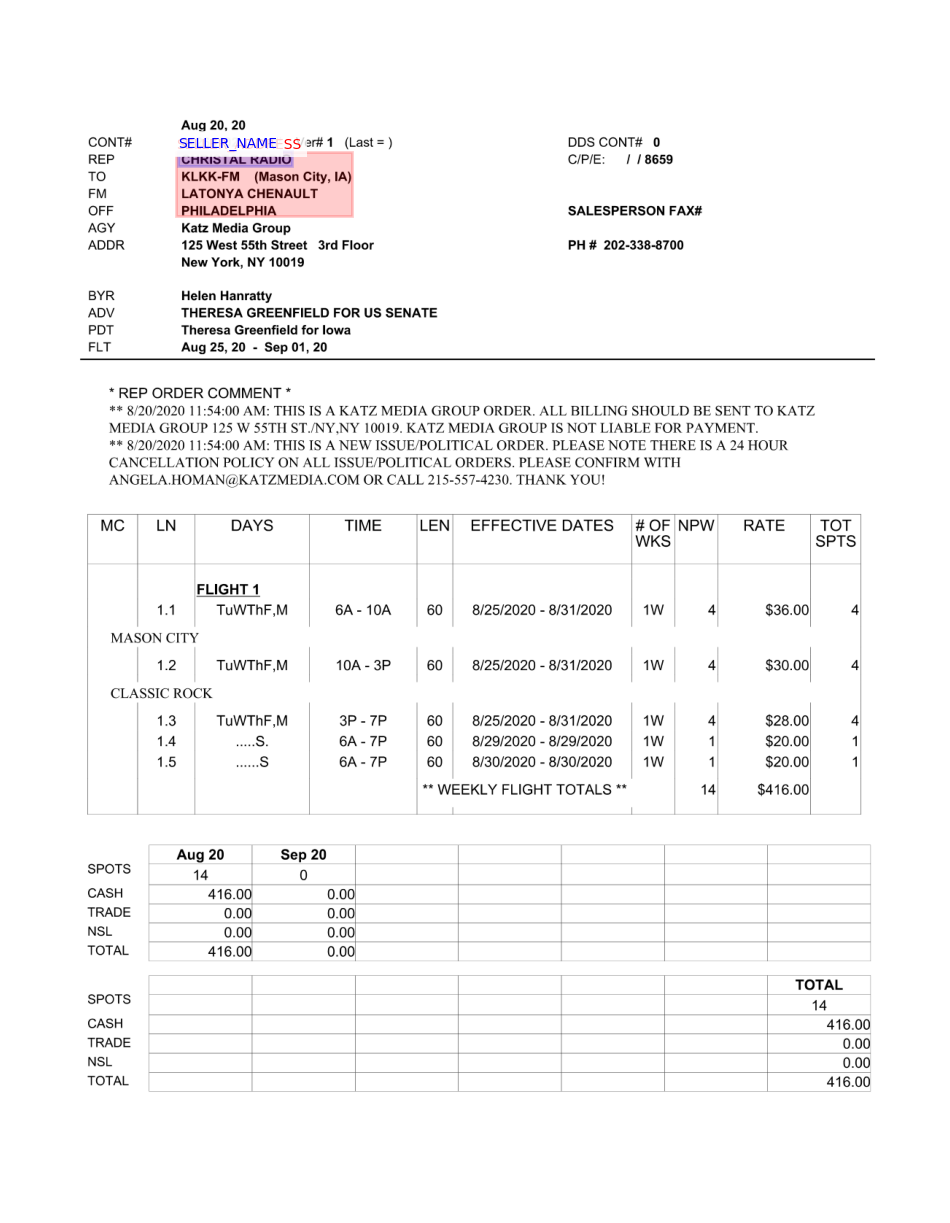

In [78]:
image_path  = "../data/interim/overlap_invoices/2e95329f4c9e48fca33538aa/page_0000.png"
show_boxes(image_path, rejected.iloc[0]['matches'])

In [79]:
processed, rejected = check_word_coverage_by_area(documents_df.iloc[1])
processed.shape, rejected.shape

((354, 7), (0, 0))

And now document 3:

In [84]:
documents_df.iloc[2]

document_id                                 bc0f7fa9819741c0b1efdc34
json_data          {"invoice": {"invoice_number": {"value": "4389...
pdf_path                           pdfs/bc0f7fa9819741c0b1efdc34.pdf
split                                                          train
text_with_boxes    [{'text': 'KQMA', 'bbox': [0.27602905569007263...
ocr_text           KQMA 92.5 FM KKAN 1490 AM POBOX548 We certify ...
Name: 4119, dtype: object

In [80]:
processed, rejected = check_word_coverage(documents_df.iloc[2])
processed.shape, rejected.shape

((125, 7), (12, 8))

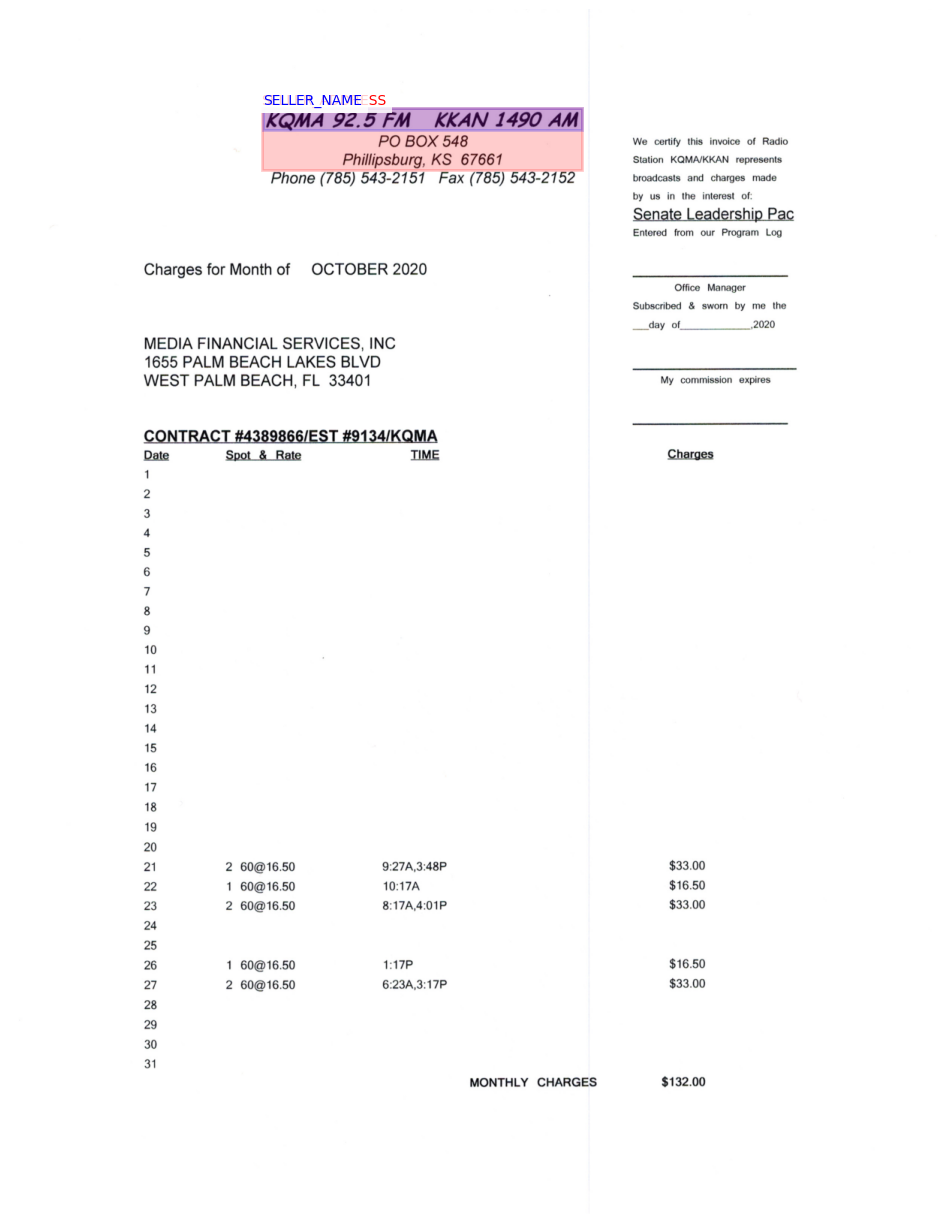

In [86]:
image_path  = "../data/interim/overlap_invoices/bc0f7fa9819741c0b1efdc34/page_0000.png"
show_boxes(image_path, rejected.iloc[0]['matches'])

In [87]:
rejected

,document_id,text,page,bbox,reason,matches,annotation_id,field
0,bc0f7fa9819741c0b1efdc34,KQMA,0,"[0.27602905569007263, 0.08598130841121496, 0.3...",ambiguous_word,"[{'annotation_id': 2, 'field': 'SELLER_ADDRESS...",NaN,NaN
1,bc0f7fa9819741c0b1efdc34,92.5,0,"[0.3474576271186441, 0.08598130841121496, 0.39...",ambiguous_word,"[{'annotation_id': 2, 'field': 'SELLER_ADDRESS...",NaN,NaN
2,bc0f7fa9819741c0b1efdc34,FM,0,"[0.3898305084745763, 0.08598130841121496, 0.43...",ambiguous_word,"[{'annotation_id': 2, 'field': 'SELLER_ADDRESS...",NaN,NaN
3,bc0f7fa9819741c0b1efdc34,KKAN,0,"[0.4570217917675545, 0.08598130841121496, 0.51...",ambiguous_word,"[{'annotation_id': 2, 'field': 'SELLER_ADDRESS...",NaN,NaN
4,bc0f7fa9819741c0b1efdc34,1490,0,"[0.5230024213075061, 0.08551401869158878, 0.57...",ambiguous_word,"[{'annotation_id': 2, 'field': 'SELLER_ADDRESS...",NaN,NaN
5,bc0f7fa9819741c0b1efdc34,AM,0,"[0.5792978208232445, 0.08551401869158878, 0.61...",ambiguous_word,"[{'annotation_id': 2, 'field': 'SELLER_ADDRESS...",NaN,NaN
6,bc0f7fa9819741c0b1efdc34,MEDIA,0,"[0.14527845036319612, 0.27289719626168224, 0.1...",ambiguous_word,"[{'annotation_id': 0, 'field': 'CLIENT_ADDRESS...",NaN,NaN
7,bc0f7fa9819741c0b1efdc34,FINANCIAL,0,"[0.20278450363196127, 0.27289719626168224, 0.2...",ambiguous_word,"[{'annotation_id': 0, 'field': 'CLIENT_ADDRESS...",NaN,NaN
8,bc0f7fa9819741c0b1efdc34,"SERVICES,",0,"[0.29418886198547217, 0.27289719626168224, 0.3...",ambiguous_word,"[{'annotation_id': 0, 'field': 'CLIENT_ADDRESS...",NaN,NaN
9,bc0f7fa9819741c0b1efdc34,INC,0,"[0.3880145278450363, 0.27289719626168224, 0.41...",ambiguous_word,"[{'annotation_id': 0, 'field': 'CLIENT_ADDRESS...",NaN,NaN


In [88]:
processed, rejected = check_word_coverage_by_area(documents_df.iloc[2])
processed.shape, rejected.shape

((135, 7), (0, 0))

Seems to be, this approach is working!

Another thing is worth checking is building ocr string from the given words

For this task, order is crucial (for both bert and layourlm), and ordering by just `x` coordinate might not be enough

In [89]:
def show_word_order(row, image_path, page=0, figsize=(18, 24)):
    """Display OCR word boxes and their reading order for one page.

    Args:
        row: Preprocessed invoice row containing text_with_boxes.
        image_path: Image of the selected document page.
        page: Zero-based page index.
        figsize: Matplotlib figure size.

    Returns:
        Figure and axes for further inspection or saving.
    """
    words = row["text_with_boxes"]
    if isinstance(words, str):
        words = json.loads(words)

    words = sorted(words, key=lambda word: word["start"])

    with Image.open(image_path) as source:
        image = source.convert("RGB")

    width, height = image.size
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(image)

    for order, word in enumerate(words, start=1):
        if int(word["page"]) != page:
            continue

        x0, y0, x1, y1 = word["bbox"]
        x, y = x0 * width, y0 * height

        ax.add_patch(Rectangle(
            (x, y),
            (x1 - x0) * width,
            (y1 - y0) * height,
            edgecolor="blue",
            facecolor="none",
            linewidth=0.6,
        ))

        ax.text(
            x, y,
            str(order),
            fontsize=6,
            color="red",
            va="bottom",
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.8,
                "pad": 0.2,
            },
        )

    ax.set_title(f"Document {row['document_id']} — page {page + 1}")
    ax.axis("off")
    plt.show()
    return fig, ax

In [91]:
documents_df.iloc[0]

document_id                                 26f0e3a78e26450b9b47dd81
json_data          {"invoice": {"invoice_number": {"value": "4969...
pdf_path                           pdfs/26f0e3a78e26450b9b47dd81.pdf
split                                                          train
text_with_boxes    [{'text': 'SONNY', 'bbox': [0.7870588235294118...
ocr_text           SONNY CUMULUS MUSKEGON 975 INVOICE Remit To: 3...
Name: 905, dtype: object

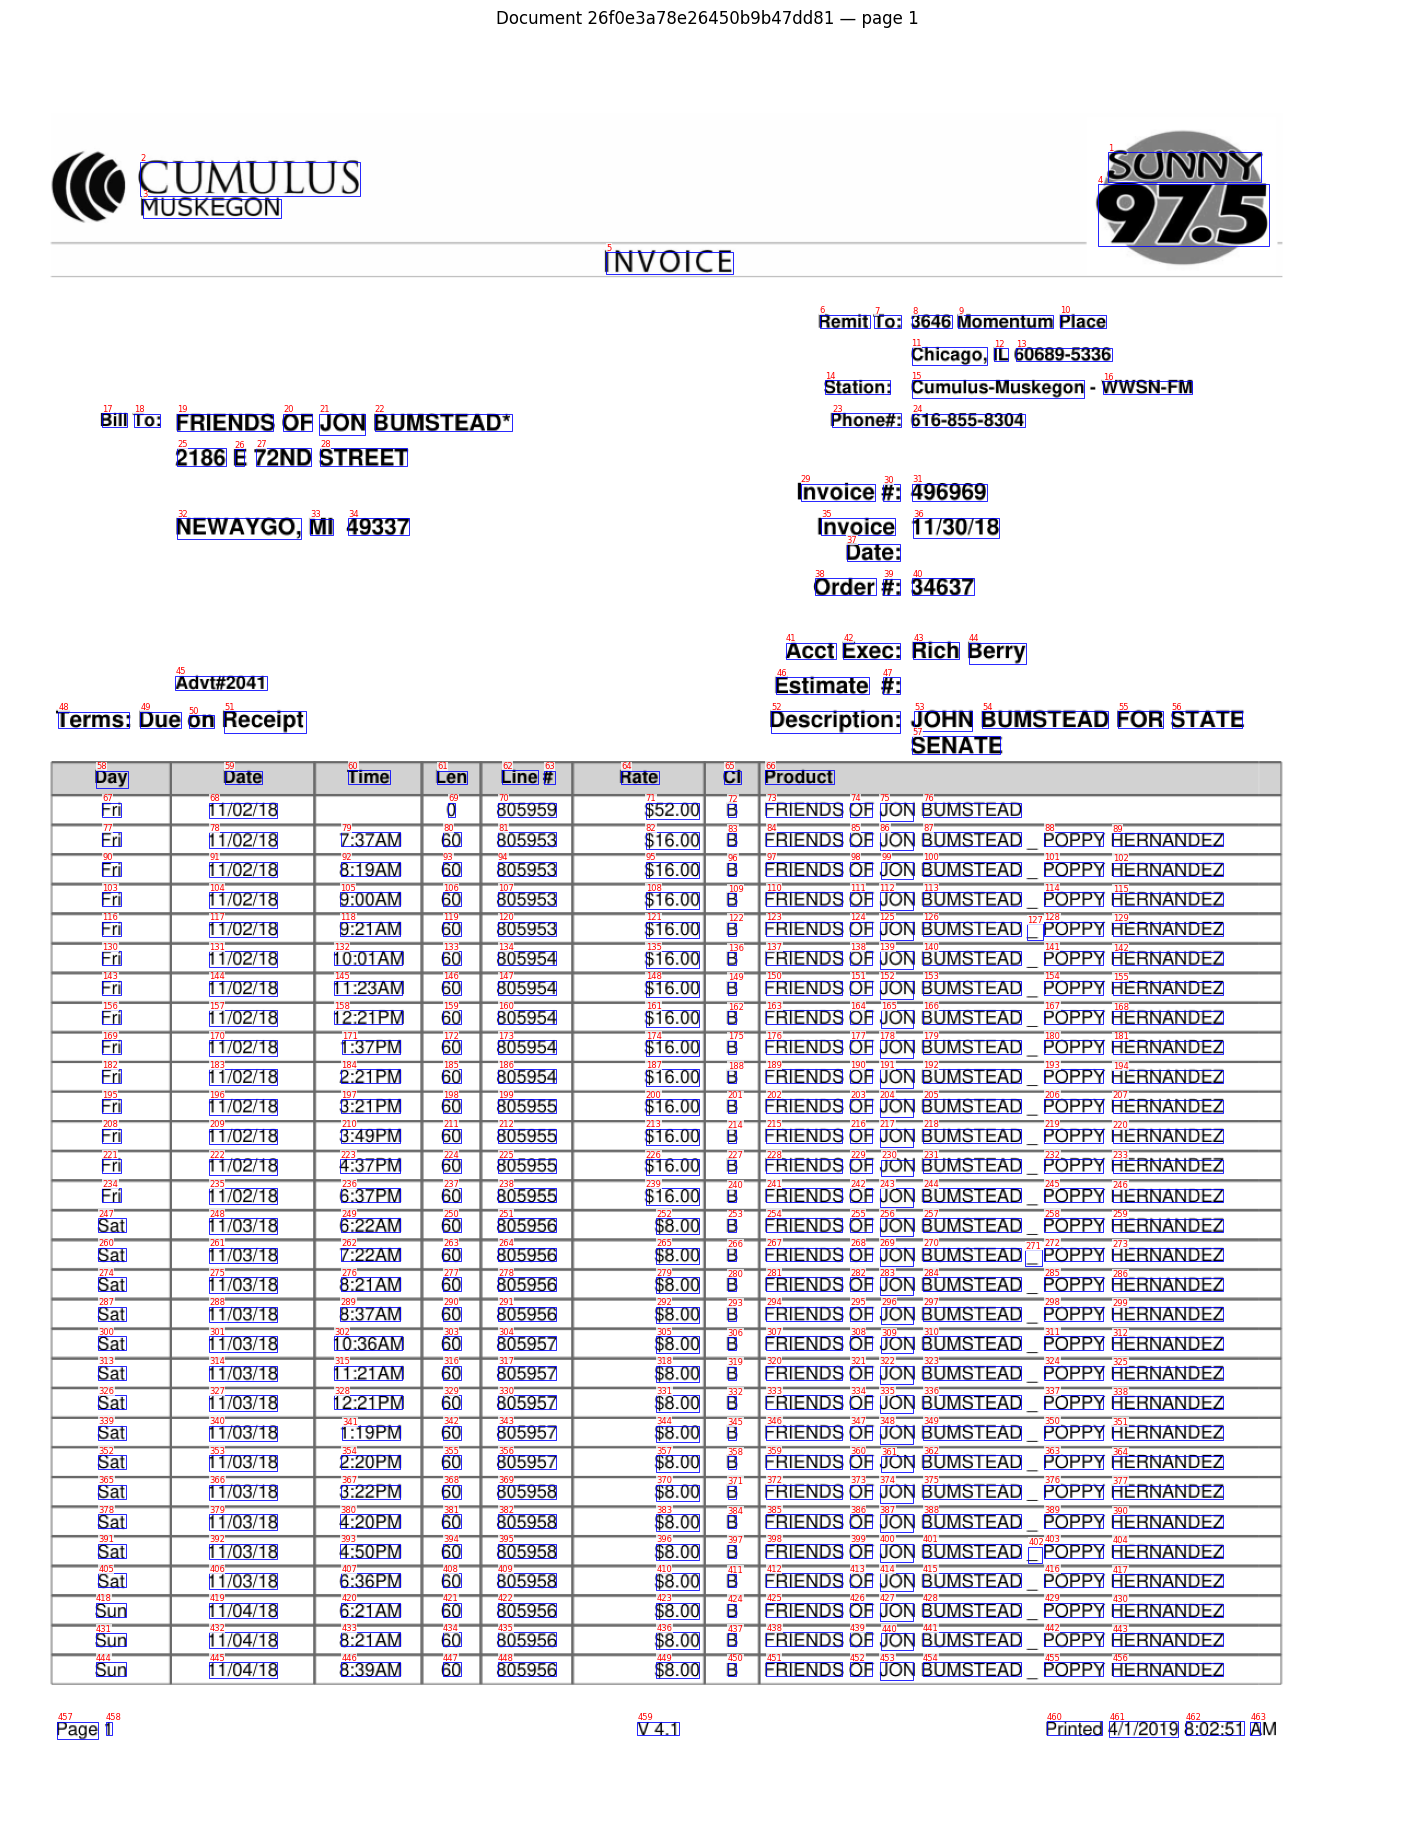

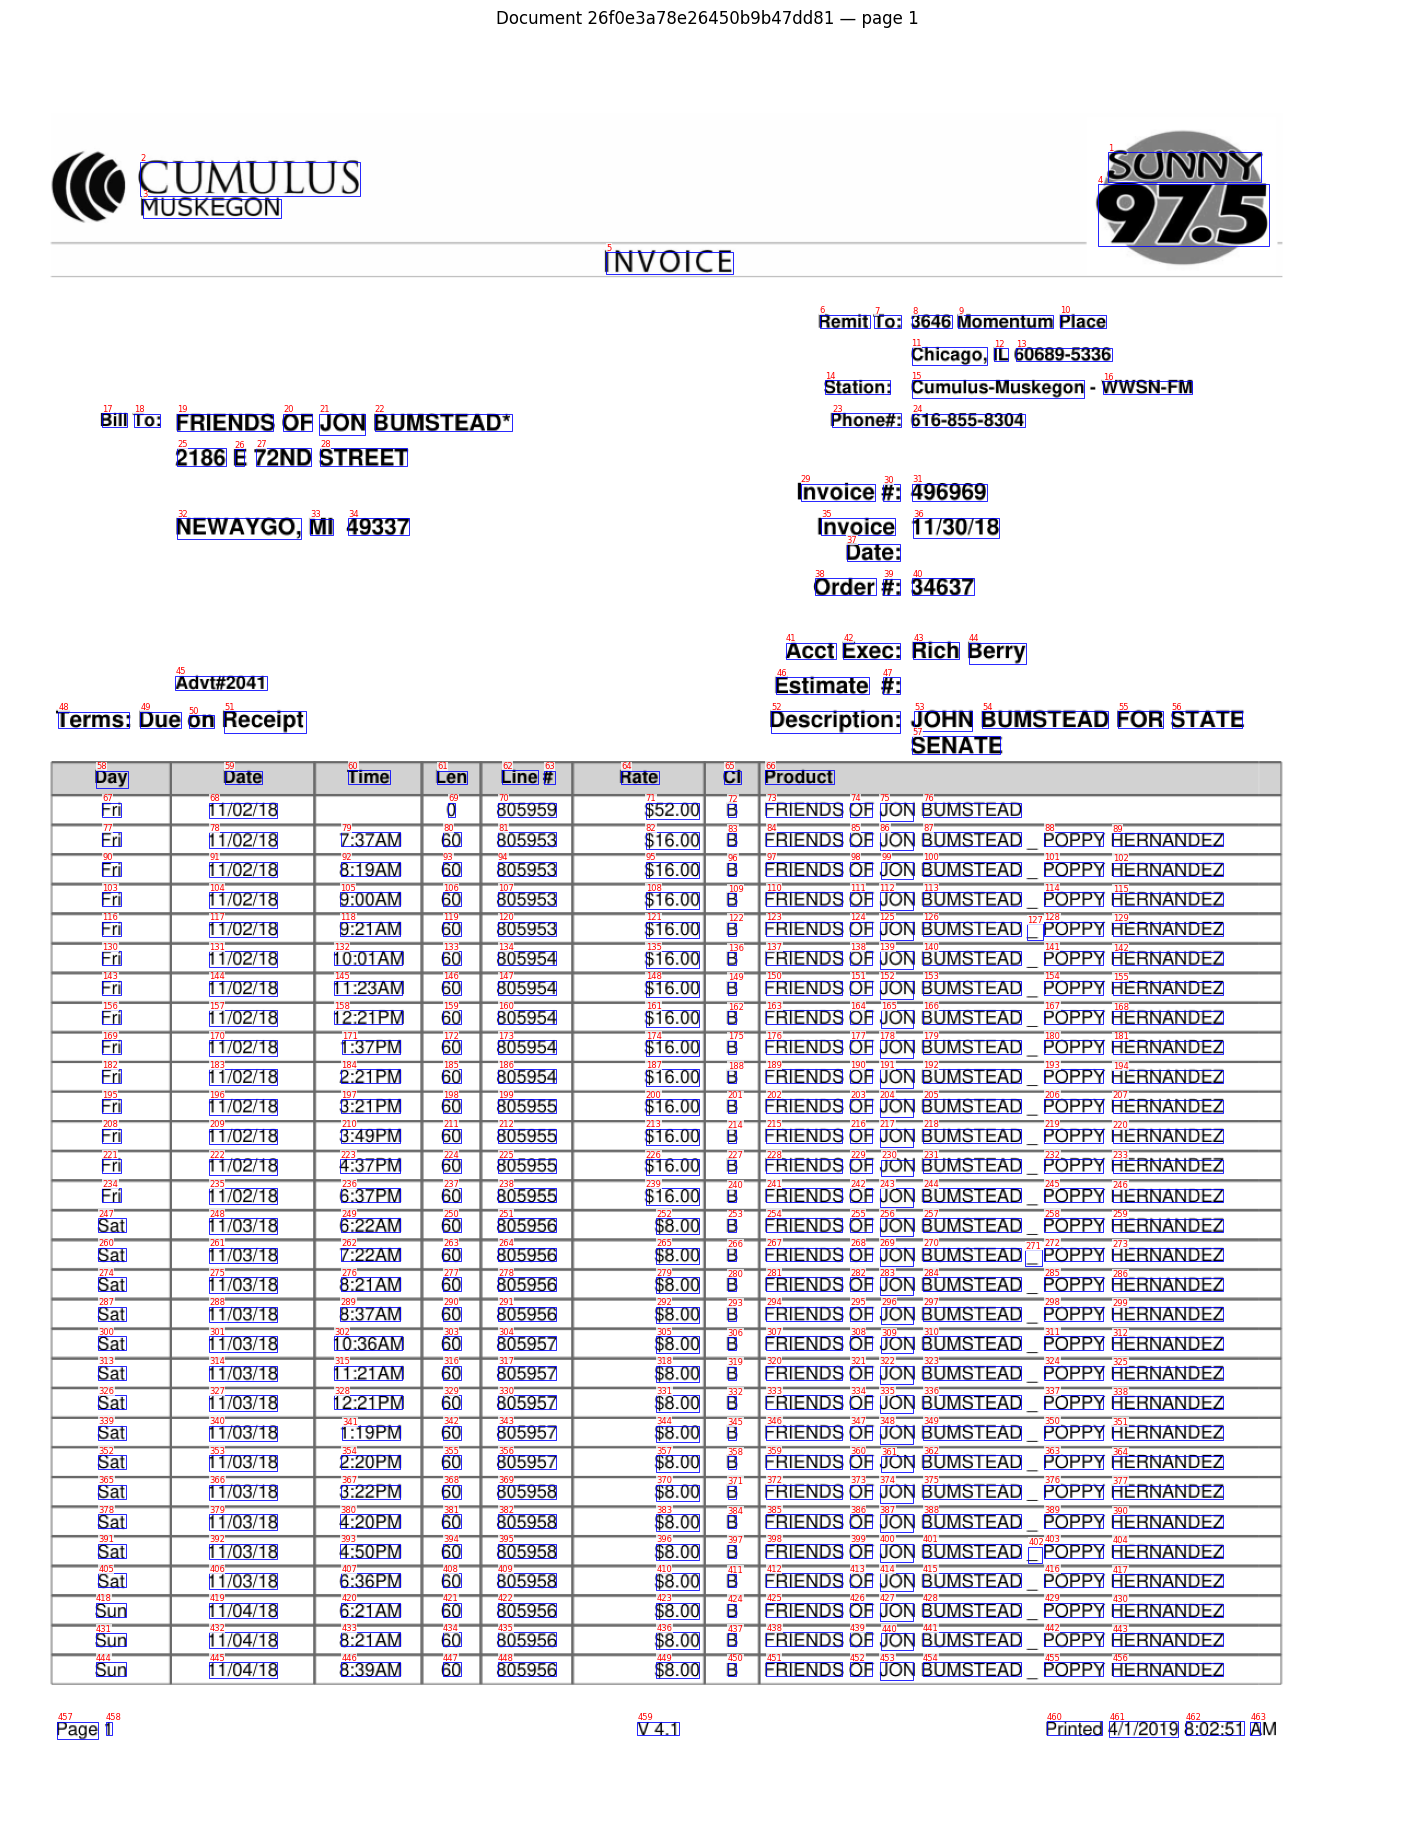

In [90]:
row = documents_df.iloc[0]
fig, ax = show_word_order(
    row,
    f"../data/interim/overlap_invoices/{row.document_id}/page_0000.png",
    page=0
)
fig

As you can see, each word processed from top left to bottom right edge of the document

The existing ordering reads the page as one wide stream of horizontal rows. It does not recognize that the left and right sides can contain separate blocks of information.

For example, 

```
FRIENDS OF JON BUMSTEAD      ← billing name
Phone#: 616-855-8304        ← unrelated right-hand block
2186 E 72ND STREET         ← billing street
Invoice #: 496969          ← unrelated right-hand block
NEWAYGO, MI 49337          ← billing city
```

Each line is readable, but _the billing address is interrupted_.

This can make learning harder in three ways:

- **Weaker text context.** Words next to each other in the sequence may belong to unrelated fields. Related address lines are farther apart.
- **Fragmented field spans.** An address interrupted by other fields cannot be represented as one continuous text span without including unrelated words. It needs several spans.
- **Less useful token windows.** A window can contain parts of several blocks while splitting a related block across window boundaries.

In order to fix this, an [XY cut](https://arxiv.org/html/2504.10258v1) approach might be used

In [92]:
import json
from statistics import median


def word_center_y(word):
    return (word["bbox"][1] + word["bbox"][3]) / 2


def widest_gap(words, axis, minimum):
    """Find the widest empty gap along X or Y."""
    intervals = sorted(
        (word["bbox"][axis], word["bbox"][axis + 2])
        for word in words
    )
    end = intervals[0][1]
    gaps = []

    for start, stop in intervals[1:]:
        if start - end >= minimum:
            gaps.append((start - end, (start + end) / 2))
        end = max(end, stop)

    return max(gaps)[1] if gaps else None


def horizontal_order(words):
    """Group words into visual lines, then read each line left to right."""
    if not words:
        return []

    tolerance = median(
        word["bbox"][3] - word["bbox"][1] for word in words
    ) * 0.5
    lines = []

    for word in sorted(
        words, key=lambda word: (word_center_y(word), word["bbox"][0])
    ):
        if (
            not lines
            or word_center_y(word)
            - median(word_center_y(item) for item in lines[-1])
            > tolerance
        ):
            lines.append([])

        lines[-1].append(word)

    return [
        word
        for line in lines
        for word in sorted(line, key=lambda word: word["bbox"][0])
    ]


def xy_cut_order(words, min_gap_x, min_gap_y):
    """Separate blocks recursively, then order words within each block."""
    if len(words) <= 1:
        return words

    for axis, minimum in ((0, min_gap_x), (1, min_gap_y)):
        cut = widest_gap(words, axis, minimum)
        if cut is None:
            continue

        first = [
            word for word in words
            if word["bbox"][axis + 2] <= cut
        ]
        second = [
            word for word in words
            if word["bbox"][axis] >= cut
        ]

        if first and second and len(first) + len(second) == len(words):
            return (
                xy_cut_order(first, min_gap_x, min_gap_y)
                + xy_cut_order(second, min_gap_x, min_gap_y)
            )

    return horizontal_order(words)


def reorder_words(row, table_y_ranges, min_gap_x=0.04, min_gap_y=0.03):
    """Return reordered word copies with rebuilt character offsets.

    Args:
        row: Row containing text_with_boxes.
        table_y_ranges: Page-to-table-interval mapping in normalized coordinates.
            Example: {0: [(0.40, 0.92)]}. Missing pages keep their order.
            An empty interval list applies XY-cut to the whole page.
        min_gap_x: Minimum horizontal gap between blocks.
        min_gap_y: Minimum vertical gap between blocks.

    Returns:
        Reordered word dictionaries. The input row remains unchanged.
    """
    if not (0 < min_gap_x <= 1 and 0 < min_gap_y <= 1):
        raise ValueError("Gap thresholds must be greater than 0 and at most 1")

    words = row["text_with_boxes"]
    if isinstance(words, str):
        words = json.loads(words)

    words = sorted(
        [dict(word) for word in words],
        key=lambda word: word["start"],
    )
    ordered = []

    for page in sorted({int(word["page"]) for word in words}):
        remaining = [
            word for word in words if int(word["page"]) == page
        ]

        if page not in table_y_ranges:
            ordered.extend(remaining)
            continue

        previous_bottom = 0
        for top, bottom in sorted(table_y_ranges[page]):
            if not 0 <= previous_bottom <= top < bottom <= 1:
                raise ValueError("Table intervals must be valid and disjoint")
            previous_bottom = bottom

            before = [
                word for word in remaining if word_center_y(word) < top
            ]
            table = [
                word for word in remaining
                if top <= word_center_y(word) <= bottom
            ]

            ordered.extend(xy_cut_order(before, min_gap_x, min_gap_y))
            ordered.extend(table)  # Keep the existing table order.

            remaining = [
                word for word in remaining if word_center_y(word) > bottom
            ]

        ordered.extend(xy_cut_order(remaining, min_gap_x, min_gap_y))

    position = 0
    for word in ordered:
        word["start"] = position
        word["end"] = position + len(word["text"])
        position = word["end"] + 1

    return ordered


In [93]:
ordered_words = reorder_words(
    row,
    table_y_ranges={0: [(0.40, 0.92)]},
)

In [95]:
image_path = f"../data/interim/overlap_invoices/{row.document_id}/page_0000.png"
experiment = row.copy()
experiment["text_with_boxes"] = ordered_words

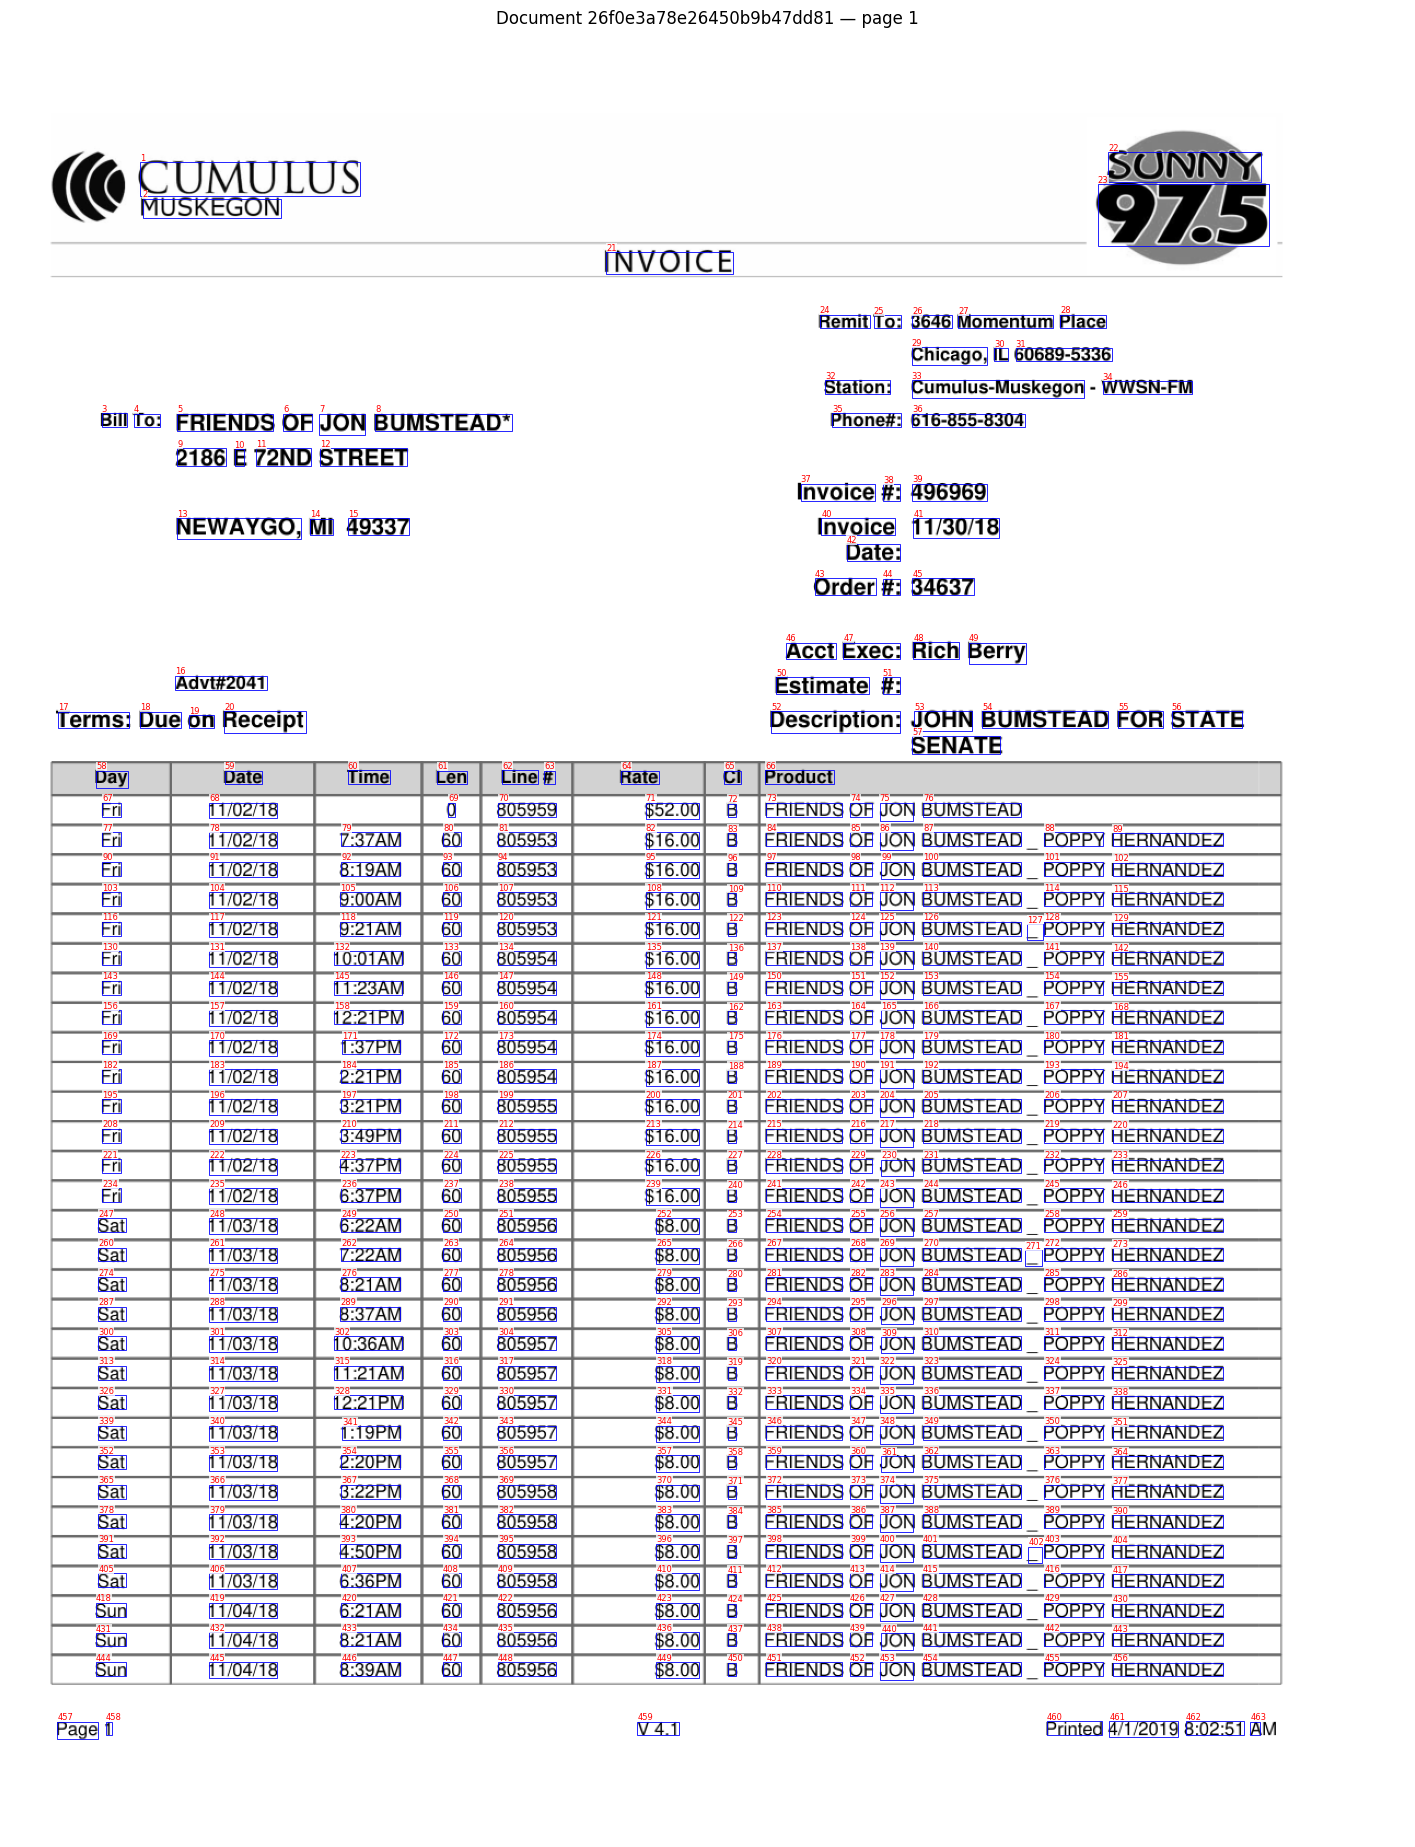

(<Figure size 1800x2400 with 1 Axes>,
 <Axes: title={'center': 'Document 26f0e3a78e26450b9b47dd81 — page 1'}>)

In [96]:
show_word_order(experiment, image_path, page=0)